# Домашнее задание: вакансии, отклики и приглашения

Подготовьте два небольших отчёта: **по городам вакансий** и **по размеру работодателя**. Нужно сравнить число вакансий, откликов и приглашений, долю приглашений среди откликов и медиану нижней границы зарплаты в рублях, количество и долю вакансий с непустой рублёвой зарплатой.

Вы сами соберёте таблицы из нескольких источников, посчитаете показатели через `groupby`, построите график и оформите результат. Все необходимые приёмы есть в лекции; SQL-запросы писать не нужно.

**Основная часть — все 8 пунктов.** Ориентир: 1,5–2,5 часа, возможно в несколько подходов. Это предварительная оценка, ещё не проверенная на студентах. В конце есть необязательные упражнения.

Откройте тетрадку из папки, в которой она сохранена. Рядом должны быть папки `data` и `outputs`. Выполняйте ячейки сверху вниз. Подсказки указывают методы и подход; готовые выражения можно посмотреть в лекции.

Сдайте эту тетрадку с кодом, сохранёнными результатами и короткими ответами, а также Excel-файл отчёта. Достаточно обычного последовательного кода: свои функции и циклы не требуются.

## Какие данные есть

Все CSV находятся в `data/sql/`.

| Файл | Что означает одна строка | Важные столбцы |
|---|---|---|
| `vacancies.csv` | Вакансия | `vacancy_id`, `employer_id`, `area_id`, `salary_from`, `currency`, `published_at` |
| `responses.csv` | Отклик | `response_id`, `vacancy_id`, `status` |
| `employers.csv` | Работодатель | `employer_id`, `employer_name`, `area_id` |
| `areas.csv` | Город | `area_id`, `area_name` |
| `employer_size_groups.csv` | Работодатель с известной группой размера | `employer_id`, `size_group` |

`status == "invited"` означает приглашение. Все статусы откликов учитываются в общем числе откликов.

`size_group`: `small` — менее 250 сотрудников, `medium` — 250–999, `large` — от 1000. Это учебные группы, уже рассчитанные в справочнике. Для одной компании группа неизвестна.

В `vacancies.area_id` указан **город вакансии**, а в `employers.area_id` — город работодателя. Они могут различаться. В отчёте нужен город вакансии.

`salary_from` — заявленная нижняя граница зарплаты. Пропуск означает, что сумма неизвестна; это не нулевая зарплата.

In [1]:
import pandas as pd
import numpy as np
%pip install pandas sqlalchemy "psycopg[binary]"
from sqlalchemy import create_engine, text
import plotly.express as px
from pathlib import Path

Note: you may need to restart the kernel to use updated packages.


## 1. Загрузите данные и осмотрите основные таблицы

1. Прочитайте пять CSV в переменные `vacancies`, `responses`, `employers`, `areas`, `size_groups`.
2. Для **`vacancies` и `responses`** выведите первые строки, размеры и общую информацию о столбцах.
3. Посчитайте пропуски в `vacancies["salary_from"]` и количество откликов каждого `status`.
4. Небольшие справочники `areas` и `size_groups` выведите целиком.

**Что получить:** представление о структуре данных, число вакансий и откликов, число неизвестных зарплат и распределение статусов. Проверять все ключи и все категории каждой таблицы не нужно.

**Методы:** `pd.read_csv`, `head`, `shape`, `info`, `isna`, `sum`, `value_counts`.

In [2]:
# 1. Чтение и осмотр
engine = create_engine(
    "postgresql+psycopg://postgres@localhost:5432/postgres"
)

import pandas as pd

tables = pd.read_sql_query(
    text("""
        SELECT table_name
        FROM information_schema.tables
        WHERE table_schema = 'hh_school'
          AND table_type = 'BASE TABLE'
        ORDER BY table_name
    """),
    engine
)["table_name"].tolist()

dataframes = {}

for table in tables:
    query = f'SELECT * FROM hh_school."{table}"'
    dataframes[table] = pd.read_sql_query(query, engine)

df_areas = dataframes["areas"]
df_calls = dataframes["calls"]
df_employers = dataframes["employers"]
df_messages = dataframes["messages"]
df_responses = dataframes["responses"]
df_vacancies = dataframes["vacancies"]
df_vacancy_details = dataframes["vacancy_details"]
df_size_groups = pd.read_csv("employer_size_groups.csv", sep=",")

print("Первые 5 строк таблицы вакансий:")
print(df_vacancies.head())
print("Размер таблицы вакансий:", df_vacancies.shape)
print("Информация о столбцах вакансий:")
df_vacancies.info()

print("\nПервые 5 строк таблицы откликов:")
print(df_responses.head())
print("Размер таблицы откликов:", df_responses.shape)
print("Информация о столбцах откликов:")
df_responses.info()

print('Количество пропусков в нижней границе зарплаты:', df_vacancies["salary_from"].isna().sum())
print('Количество откликов по каждому статусу:', df_responses["status"].value_counts())

print("\nСправочник городов:")
print(df_areas)
print("\nСправочник размера групп:")
print(df_size_groups)

Первые 5 строк таблицы вакансий:
   vacancy_id  employer_id  area_id             vacancy_name  \
0        1001          101        1  Стажёр: аналитик данных   
1        1002          101        1   Senior аналитик данных   
2        1003          101        1   Senior аналитик данных   
3        1004          101        1  Стажёр: аналитик данных   
4        1005          102        1  Стажёр: аналитик данных   

  professional_role     experience        employment  salary_from  salary_to  \
0   Аналитик данных      Нет опыта        Стажировка      35000.0    45000.0   
1   Аналитик данных  От 3 до 6 лет  Полная занятость     140000.0   165000.0   
2   Аналитик данных  От 3 до 6 лет  Полная занятость     135000.0   165000.0   
3   Аналитик данных      Нет опыта        Стажировка      40000.0    50000.0   
4   Аналитик данных      Нет опыта        Стажировка      40000.0    55000.0   

  currency        published_at           closed_at  
0      RUR 2026-05-14 06:00:00                 N

## 2. Подготовьте зарплаты и дату публикации

1. Преобразуйте `vacancies["published_at"]` в дату/время.
2. Создайте в `vacancies` столбец `salary_rur`: значение из `salary_from`, если `currency == "RUR"`, иначе `NaN`.
3. Выведите первые строки со столбцами `salary_from`, `currency`, `salary_rur`, `published_at`.

**Зачем:** в медиану не должны попадать суммы в других валютах. Зарплаты не нужно пересчитывать, заполнять нулями или усреднять между `salary_from` и `salary_to`.

**Методы:** `pd.to_datetime`; для условного столбца подойдёт `np.where` или присваивание через `loc`.

In [3]:
# 2. Подготовка
df_vacancies["published_at"] = pd.to_datetime(df_vacancies["published_at"])
salary_rur = np.where(df_vacancies["currency"] == "RUR", df_vacancies["salary_from"], np.nan)
df_vacancies["salary_rur"] = salary_rur
print(df_vacancies[["salary_from","currency","salary_rur","published_at"]].head())

   salary_from currency  salary_rur        published_at
0      35000.0      RUR     35000.0 2026-05-14 06:00:00
1     140000.0      RUR    140000.0 2026-05-29 06:00:00
2     135000.0      RUR    135000.0 2026-06-23 06:00:00
3      40000.0      RUR     40000.0 2026-01-13 06:00:00
4      40000.0      RUR     40000.0 2026-06-03 06:00:00


### 2.1. Сравните заполненность зарплат по валютам

После создания `salary_rur` вернитесь к исходному столбцу `salary_from`. Для каждого значения `currency` выведите:

- число строк;
- число непустых значений `salary_from`;
- среднее значение `salary_from`.

Используйте один `groupby` по валюте, отбор `salary_from` и список агрегатных функций `size`, `count`, `mean`. Включите в результат и строки с неизвестной валютой: для этого в `groupby` есть параметр `dropna=False`.

Коротко поясните разницу между `size` и `count`. Значения разных валют между собой усреднять не нужно; здесь каждая группа считается отдельно.

In [4]:
# 2.1. Зарплаты по валютам
salary_by_currency = df_vacancies.groupby("currency", dropna=False)["salary_from"].agg(["size","count", "mean"])
print(salary_by_currency)

#сount не учитывает пустые значения колонки, а size - учитывает

          size  count          mean
currency                           
RUR         44     44  76590.909091
NaN          8      0           NaN


## 3. Соберите таблицу вакансий со справочниками

Получите DataFrame `df`, в котором **одна строка по-прежнему соответствует одной вакансии**.

Последовательно добавьте к `vacancies`:

1. `employer_name` из `employers` — по `employer_id`. Из справочника работодателей возьмите только ID и название, чтобы не добавить второй `area_id`.
2. `area_name` из `areas` — по `area_id`. Переименуйте `area_name` в `city`.
3. `size_group` из `size_groups` — по `employer_id`. Пропущенную группу заполните строкой `"unknown"`.

Во всех трёх случаях используйте **левое соединение**, чтобы сохранить все вакансии.

**Что вывести:** размер `df` и первые строки со столбцами `vacancy_id`, `employer_name`, `city`, `size_group`. После объединений должно остаться **52 строки**.

**Методы:** выбор списка столбцов, `merge`, `rename`, `fillna`.

In [5]:
# 3. Вакансии и справочники
df = df_vacancies.copy()
df = df.merge(
    df_employers[["employer_id", "employer_name"]],
    on = 'employer_id',
    how = 'left',
    validate = 'many_to_one'
)

df = df.merge(
    df_areas[["area_id", "area_name"]],
    on = "area_id",
    how = "left",
    validate = "many_to_one"
)

df = df.rename(columns={"area_name": "city"})

df = df.merge(
    df_size_groups[['employer_id', 'size_group']],
    on = 'employer_id',
    how = 'left',
    validate = 'many_to_one'
)

df["size_group"] = df["size_group"].fillna("unknown")

print("Размер df:", df.shape)
print(df[["vacancy_id", "employer_name", "city", "size_group"]].head())

Размер df: (52, 16)
   vacancy_id employer_name    city size_group
0        1001     ТехноБанк  Москва      large
1        1002     ТехноБанк  Москва      large
2        1003     ТехноБанк  Москва      large
3        1004     ТехноБанк  Москва      large
4        1005     Мосмаркет  Москва      large


## 4. Добавьте число откликов и приглашений на вакансию

1. В `responses` создайте `is_invited`: `True`, если `status == "invited"`, иначе `False`.
2. Сгруппируйте отклики по `vacancy_id`. Получите таблицу `response_counts` с двумя показателями:
   - `responses` — количество `response_id`;
   - `invited` — сумма `is_invited` (`True` при суммировании считается как 1).
3. Присоедините эту таблицу к `df` по `vacancy_id` левым соединением.
4. В столбцах `responses` и `invited` заполните пропуски нулями: здесь они означают отсутствие откликов.
5. Выведите первые строки с ID вакансии и двумя новыми показателями. Посчитайте, у скольких вакансий `responses == 0`.

**Важно:** сначала считаем отклики на вакансию, затем соединяем. Прямое присоединение исходных откликов повторит строки вакансий, и их количество в отчёте станет неверным.

**Методы:** сравнение, `groupby`, именованное `agg`, `reset_index`, `merge`, `fillna`, маска или сумма логического условия.

**Самопроверка:** в `df` всё ещё 52 строки, сумма `responses` — **628**, сумма `invited` — **92**, без откликов — **10 вакансий**. Для проверки достаточно вывести числа; писать `assert` не требуется.

In [6]:
# 4. Отклики на вакансию
df_responses["is_invited"] = df_responses["status"] == "invited"
response_counts = df_responses.groupby("vacancy_id").agg(
    responses = ("response_id", "count"),
    invited = ("is_invited", "sum")
).reset_index()
df = df.merge(
    response_counts,
    on = 'vacancy_id',
    how = 'left'
)
df[["responses", "invited"]] = (
    df[["responses", "invited"]].fillna(0).astype(int)
)
print(df[["vacancy_id","responses","invited"]].head())
print(f'Вакансий без откликов -{(df["responses"] == 0).sum()}')

   vacancy_id  responses  invited
0        1001         25        3
1        1002         19        1
2        1003         25        0
3        1004         46        6
4        1005         32        7
Вакансий без откликов -10


## 5. Постройте отчёт по городам

Создайте `city_report`, сгруппировав `df` по `city`.

| Столбец отчёта | Как посчитать |
|---|---|
| `city` | Город вакансии |
| `vacancies` | Количество `vacancy_id` |
| `responses` | Сумма `responses` |
| `invited` | Сумма `invited` |
| `median_salary` | Медиана `salary_rur` |
| `salary_count` | Число непустых значений `salary_rur` |
| `salary_share` | `salary_count / vacancies` в готовом отчёте |
| `invitation_share` | `invited / responses` в готовом отчёте |

Отсортируйте отчёт по числу откликов по убыванию и выведите целиком.

**Подсказка:** в одном `groupby().agg()` можно задать название каждого нового столбца и пару «исходный столбец, функция». После агрегации используйте `reset_index()` или заранее задайте `as_index=False`.

Количество и доля непустых зарплат относятся к `salary_rur`: это известные нижние суммы в рублях. Знаменатель `salary_share` — **все вакансии группы**, включая вакансии без зарплаты.

Долю приглашений считайте **из итоговых чисел по городу**, а не как среднее долей отдельных вакансий. В случае 0 приглашений и 0 откликов обычное деление даёт `NaN`; нулём его заменять не нужно.

**Самопроверка:** 5 городов; сумма `vacancies` — 52, сумма `responses` — 628.

In [7]:
# 5. Отчёт по городам
city_report = df.groupby('city').agg(
    vacancies = ('vacancy_id','count'),
    responses = ('responses', 'sum'),
    invited = ('invited','sum'),
    median_salary = ('salary_rur','median'),
    salary_count = ('salary_rur', 'count')
).reset_index()

city_report['salary_share'] = (
    city_report['salary_count']/city_report['vacancies']
)
city_report['invitation_share'] = (
    city_report['invited']
    .div(city_report['responses'].replace(0, float('nan')))
)

city_report = city_report.sort_values(
    by='responses', ascending=False
).copy()

city_report['median_salary'] = city_report['median_salary'].round(0)
city_report['salary_share'] = (city_report['salary_share'] * 100).round(1)
city_report['invitation_share'] = (city_report['invitation_share'] * 100).round(1)

city_report = city_report.rename(columns={
    'city': 'Город',
    'vacancies': 'Вакансии',
    'responses': 'Отклики',
    'invited': 'Приглашения',
    'median_salary': 'Медианная зарплата, ₽',
    'salary_count': 'Вакансии с указанной зарплатой',
    'salary_share': 'Доля вакансий с зарплатой, %',
    'invitation_share': 'Доля приглашений от откликов, %'
})

display(city_report)

,Город,Вакансии,Отклики,Приглашения,"Медианная зарплата, ₽",Вакансии с указанной зарплатой,"Доля вакансий с зарплатой, %","Доля приглашений от откликов, %"
2,Москва,26,405,54,52500.0,22,84.6,13.3
0,Екатеринбург,7,80,16,60000.0,6,85.7,20.0
4,Санкт-Петербург,9,62,10,60000.0,9,100.0,16.1
1,Казань,4,54,6,80000.0,3,75.0,11.1
3,Новосибирск,6,27,6,50000.0,4,66.7,22.2


## 6. Постройте такой же отчёт по размеру работодателя

Создайте `size_report` с теми же семью показателями, что в предыдущем пункте, но группируйте по `size_group`.

1. Сохраните группу `unknown`: неизвестный размер компании не означает, что её вакансии и отклики нужно исключить.
2. Отсортируйте отчёт по `invitation_share` по убыванию и выведите его.
3. Посмотрите, какая из известных групп (`small`, `medium`, `large`) имеет наибольшую долю приглашений.

**Подсказка:** повторите логику предыдущего пункта с другой колонкой группировки. Выносить её в отдельную функцию не нужно.

**Самопроверка:** 4 группы, включая `unknown`; итоговые количества вакансий, откликов и приглашений совпадают с отчётом по городам.

In [8]:
# 6. Отчёт по размеру работодателя
size_report = df.groupby('size_group').agg(
    vacancies = ('vacancy_id','count'),
    responses = ('responses', 'sum'),
    invited = ('invited','sum'),
    median_salary = ('salary_rur','median'),
    salary_count = ('salary_rur', 'count')
).reset_index()

size_report['salary_share'] = (
    size_report['salary_count']/size_report['vacancies']
)
size_report['invitation_share'] = (
    size_report['invited']
    .div(size_report['responses'].replace(0, float('nan')))
)

size_report = size_report.sort_values(
    by='invitation_share', ascending=False
).copy()

size_report['median_salary'] = size_report['median_salary'].round(0)
size_report['salary_share'] = (size_report['salary_share'] * 100).round(1)
size_report['invitation_share'] = (size_report['invitation_share'] * 100).round(1)

size_report = size_report.rename(columns={
    'size_group': 'Размер работодателя',
    'vacancies': 'Вакансии',
    'responses': 'Отклики',
    'invited': 'Приглашения',
    'median_salary': 'Медианная зарплата, ₽',
    'salary_count': 'Вакансии с указанной зарплатой',
    'salary_share': 'Доля вакансий с зарплатой, %',
    'invitation_share': 'Доля приглашений от откликов, %'
})

display(size_report)

# Наибольшая доля приглашений у работодателей medium - 18,7%

,Размер работодателя,Вакансии,Отклики,Приглашения,"Медианная зарплата, ₽",Вакансии с указанной зарплатой,"Доля вакансий с зарплатой, %","Доля приглашений от откликов, %"
1,medium,13,134,25,55000.0,12,92.3,18.7
0,large,25,287,43,50000.0,22,88.0,15.0
3,unknown,2,24,3,135000.0,1,50.0,12.5
2,small,12,183,21,75000.0,9,75.0,11.5


## 7. Оформите таблицу, постройте график и сохраните отчёт

1. Отобразите `city_report` через `.style.format()`: обе доли (`invitation_share` и `salary_share`) — в процентах с одним знаком после запятой, медианная зарплата — без дробной части, пропуски — прочерком. Остальные украшения необязательны.
2. Постройте столбчатый график Plotly Express по `city_report`: по X — город, по Y — количество откликов. Добавьте понятный заголовок.
3. Сохраните `city_report` в `outputs/vacancies_report_v2.xlsx` без индекса DataFrame.

**Методы:** `style.format` с форматами `"{:.1%}"` и `"{:,.0f}"`, параметр `na_rep`; `px.bar`; `to_excel`.

В Excel достаточно сохранить обычную таблицу. Переносить туда оформление Styler не требуется.

In [9]:
# 7. Оформление таблицы
city_report = df.groupby('city').agg(
    vacancies = ('vacancy_id','count'),
    responses = ('responses', 'sum'),
    invited = ('invited','sum'),
    median_salary = ('salary_rur','median'),
    salary_count = ('salary_rur', 'count')
).reset_index()

city_report['salary_share'] = (
    city_report['salary_count']/city_report['vacancies']
)
city_report['invitation_share'] = (
    city_report['invited']
    .div(city_report['responses'].replace(0, float('nan')))
)

city_report = city_report.sort_values(
    by='responses', ascending=False
).copy()

city_report['median_salary'] = city_report['median_salary'].round(0)

city_report = city_report.rename(columns={
    'city': 'Город',
    'vacancies': 'Вакансии',
    'responses': 'Отклики',
    'invited': 'Приглашения',
    'median_salary': 'Медианная зарплата, ₽',
    'salary_count': 'Вакансии с указанной зарплатой',
    'salary_share': 'Доля вакансий с зарплатой, %',
    'invitation_share': 'Доля приглашений от откликов, %'
})

display(
    city_report.style.format({
        'Доля вакансий с зарплатой, %': '{:.1%}',
        'Доля приглашений от откликов, %': '{:.1%}',
        'Медианная зарплата, ₽': '{:.0f}',
    }, na_rep='—').hide(axis='index')
)

Город,Вакансии,Отклики,Приглашения,"Медианная зарплата, ₽",Вакансии с указанной зарплатой,"Доля вакансий с зарплатой, %","Доля приглашений от откликов, %"
Москва,26,405,54,52500,22,84.6%,13.3%
Екатеринбург,7,80,16,60000,6,85.7%,20.0%
Санкт-Петербург,9,62,10,60000,9,100.0%,16.1%
Казань,4,54,6,80000,3,75.0%,11.1%
Новосибирск,6,27,6,50000,4,66.7%,22.2%


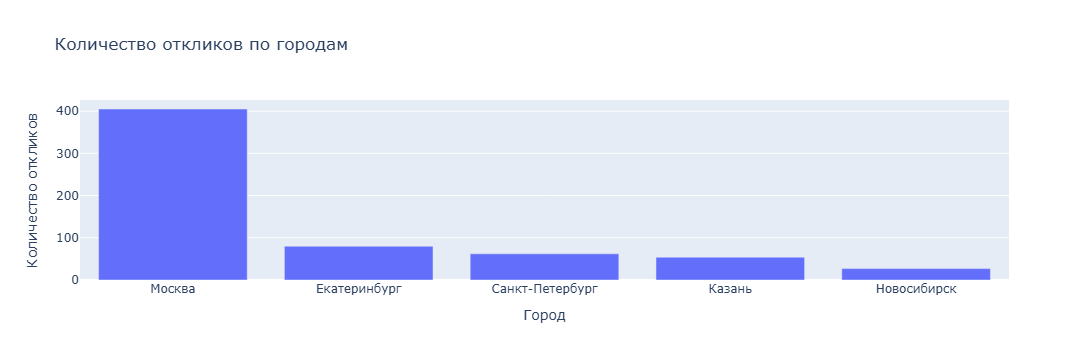

In [10]:
# 7. График и Excel
fig = px.bar(
    city_report,
    x='Город',
    y='Отклики',
    title='Количество откликов по городам',
    labels={
        'Город': 'Город',
        'Отклики': 'Количество откликов'
    }
)
fig.show()

Path('outputs').mkdir(parents=True, exist_ok=True)
city_report.to_excel(
    'outputs/vacancies_report_v2.xlsx',
    index=False
)

## 8. Ответьте на три вопроса

Достаточно 1–2 предложений на каждый вопрос.

1. В каком городе больше всего откликов? Сколько там откликов и вакансий?
2. У какой известной группы размера работодателя самая высокая доля приглашений? Укажите долю и числа приглашений и откликов, по которым она рассчитана.
3. Почему полученную медиану нельзя назвать «медианной зарплатой всех вакансий»? Укажите, какие значения использованы и какие не вошли в расчёт.

**Готовность основной части:** есть таблица на уровне вакансии, два отчёта, форматированная таблица, график, Excel-файл и три ответа. Контрольные количества совпадают.

**Ваши ответы:**

1. В Москве больше всего откликов - 405 откликов на 26 вакансий.
2. У группы medium самая большая доля приглашений - 18,7%. 25 приглашений из 134 откликов.
3. Нынешняя медианная зарплата взята из списка вакансий в базе данных, у которых указана нижняя граница зарплаты и чья зарплата указана в рублях. Вакансии, не соответствующие этим требованиям в расчет не вошли.

## Дополнительно, по желанию

### А. Сводная «город × размер работодателя»

По `df` постройте широкую таблицу: строки — `city`, столбцы — `size_group`, значения — количество `vacancy_id`. Отсутствующие сочетания заполните нулями.

**Метод:** `pivot_table`, агрегатная функция `count`.

### Б. Второй график

Постройте столбчатую диаграмму доли приглашений по `size_report`, исключив `unknown`. Добавьте в подсказку при наведении `invited` и `responses`, чтобы вместе с долей видеть объём данных.

**Методы:** фильтр по условию, `px.bar`, `hover_data`.

Эти два упражнения не нужны для завершения основной части.

In [11]:
# Дополнительно А. Сводная таблица
city_size_report = df.pivot_table(
    index='city',
    columns='size_group',
    values='vacancy_id',
    aggfunc='count',
    fill_value=0
)

display(city_size_report)

size_group,large,medium,small,unknown
city,,,,
Екатеринбург,0,7,0,0
Казань,1,0,3,0
Москва,17,0,7,2
Новосибирск,4,0,2,0
Санкт-Петербург,3,6,0,0


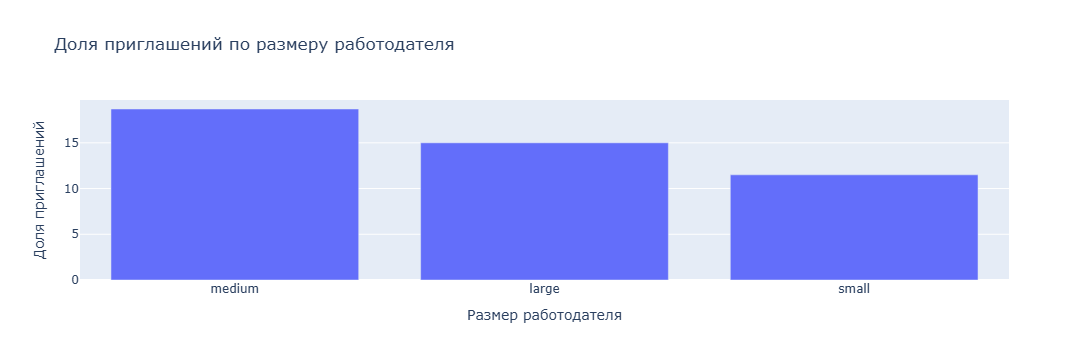

In [12]:
# Дополнительно Б. Доли приглашений на графике
import plotly.express as px

size_report_plot = size_report[
    size_report['Размер работодателя'] != 'unknown'
].copy()

fig = px.bar(
    size_report_plot,
    x='Размер работодателя',
    y='Доля приглашений от откликов, %',
    title='Доля приглашений по размеру работодателя',
    labels={
        'работодателя': 'Размер работодателя',
        'Доля приглашений от откликов, %': 'Доля приглашений',
        'Приглашения': 'Приглашения',
        'Отклики': 'Отклики'
    },
    hover_data=['Приглашения', 'Отклики']
)

fig.update_yaxes(tickformat=':{:.1%}')
fig.show()